# ЛР3. SR-inpainting на SUPIR: улучшение только фрагмента по маске (чистый Python)

Метод **A**: на каждом шаге сэмплера вне маски латент заменяется «зашумлённым исходником»
`x ← m·x_gen + (1−m)·(z_ref + σ_next·ε_fixed)` (RePaint / Blended Diffusion). Baseline **C**: SUPIR на всём изображении + попиксельная склейка по маске. **LQ** — вход без обработки.

**Как запускать:** выполняйте ячейки сверху вниз. Правится только ячейка 1 (пути и параметры).
Исходники SUPIR не меняются: нужен клон https://github.com/Fanghua-Yu/SUPIR, его зависимости и веса (SDXL base 1.0, SUPIR-v0Q), пути к весам — в `options/SUPIR_v0.yaml` и `CKPT_PTH.py` SUPIR.
`USE_FAKE=True` проверяет каркас эксперимента без SUPIR (метрики тогда **не** относятся к диффузии).

Не проверено: запуск SUPIR (нет GPU/весов в моём окружении), Mac/MPS (код SUPIR жёстко использует `cuda`), хватает ли 20 ГБ.

## 1. Параметры (редактировать только здесь)

In [1]:
SUPIR_ROOT   = "SUPIR"            # клон репозитория SUPIR ВНУТРИ текущей папки (git clone ... SUPIR); вне cwd нельзя
HR_DIR       = "DIV2K_valid_HR"   # папка с эталонами (png/jpg)
LQ_DIR       = None               # готовые LQ (например DIV2K_valid_LR_bicubic/X4); None = генерировать деградации
OUT          = "results"
PROFILE      = "mac"              # "cuda20gb" | "mac" | None (авто: macOS -> mac, иначе cuda20gb)
USE_FAKE     = False              # True = без SUPIR, только проверка каркаса
CROP, SCALE  = 256, 4             # центральный кроп эталона и коэффициент деградации
LIMIT, SEED  = 1, 1234            # число изображений, seed
STEPS        = None               # None = из профиля (50 на NVIDIA / 20 на Mac)
DEGRADATIONS = ["bicubic4x", "unknown", "realesrgan"]
MASKS        = ["ones", "zeros", "left_half", "center", "circle", "combined"]
HARD_COMPOSITE = False            # метод A: вне маски жёстко вернуть исходные пиксели
SIGN, SDXL_CKPT, SUPIR_CKPT = "Q", None, None   # None = пути из options/SUPIR_v0.yaml
SDXL_CKPT = "models/sd_xl_base_1.0_0.9vae.safetensors"
SUPIR_CKPT = "models/SUPIR-v0F.ckpt"
USE_LPIPS, USE_CLIPIQA, METRICS_DEVICE = True, True, "cpu"

## 2. Зависимости и профили платформы
`pip install` нужен один раз (раскомментируйте). Для SUPIR ставьте зависимости из его `requirements.txt`.

In [2]:
# %pip install numpy pillow opencv-python pandas matplotlib lpips pyiqa omegaconf
import os, sys, io, time, random, platform, glob
os.environ["TORCH_HOME"] = os.path.join(os.getcwd(), ".cache", "torch")   # веса lpips/pyiqa - в текущую папку, не в ~/.cache
os.environ["HF_HOME"]    = os.path.join(os.getcwd(), ".cache", "hf")
import numpy as np, pandas as pd, cv2
import matplotlib.pyplot as plt
from PIL import Image

PROFILES = {
    # NVIDIA ~20 ГБ: крупнее изображения, больше шагов. ЗНАЧЕНИЯ - СТАРТОВЫЕ ОЦЕНКИ, не измерены.
    "cuda20gb": dict(name="cuda20gb", device="cuda", diff_dtype="fp16", ae_dtype="fp32",
                     min_size=1024, max_side=1024, edm_steps=50, vae_encoder_tile=512, vae_decoder_tile=64,
                     sampler_tile=128, sampler_tile_stride=64, half_params=True, mask_feather_sigma=1.5),
    # Mac (Apple Silicon, MPS): меньше размеры, 20 шагов, мелкие тайлы. Запуск SUPIR на MPS НЕ проверен.
    # "mac":      dict(name="mac", device="mps", diff_dtype="fp16", ae_dtype="fp32",
    #                  min_size=512, max_side=512, edm_steps=10, vae_encoder_tile=256, vae_decoder_tile=32,
    #                  sampler_tile=64, sampler_tile_stride=32, half_params=True, mask_feather_sigma=1.5),
        
    "mac": dict(
        name="mac",
        device="mps",
    
        # Precision
        diff_dtype="fp32",
        ae_dtype="fp32",
        half_params=True,
    
        # Image dimensions
        min_size=256,
        max_side=736, #384,
    
        # Sampling
        edm_steps=20,
        sampler_tile=32,
        sampler_tile_stride=24,
    
        # VAE
        vae_encoder_tile=128,
        vae_decoder_tile=32,
    
        # Mask
        mask_feather_sigma=1.5,
    ),

}
def get_profile(name=None, **over):
    name = name or os.environ.get("LAB3_PROFILE") or ("mac" if platform.system() == "Darwin" else "cuda20gb")
    p = dict(PROFILES[name]); p.update({k: v for k, v in over.items() if v is not None}); return p

prof = get_profile(PROFILE, edm_steps=STEPS)
prof["sampler_tile"] = 32        # Уменьшаем размер кусочка со стандартных 128/256 до безопасных 64
prof["sampler_tile_stride"] = 24 # Шаг сетки тайлов
# Отключаем тайлинг VAE, так как на Mac он вызывает аппаратный сбой Conv2d
# ПРЯМОЙ ФИКС ДЛЯ ОТКЛЮЧЕНИЯ TILED VAE НА MAC:
# Выставляем в 0, чтобы условие `if profile["vae_encoder_tile"] > 0` вернуло False
# и функция init_tile_vae() вообще не вызывалась!
prof["vae_encoder_tile"] = 0
prof["vae_decoder_tile"] = 0

print("профиль:", prof)


профиль: {'name': 'mac', 'device': 'mps', 'diff_dtype': 'fp32', 'ae_dtype': 'fp32', 'half_params': True, 'min_size': 256, 'max_side': 736, 'edm_steps': 20, 'sampler_tile': 32, 'sampler_tile_stride': 24, 'vae_encoder_tile': 0, 'vae_decoder_tile': 0, 'mask_feather_sigma': 1.5}


## 3. Маски и перевод маски в латентное разрешение
Маска `uint8 [H,W]` (1 = улучшать) того же разрешения, что вход. Латент = ÷8, поэтому: среднее по блокам 8×8 → гауссово размытие σ (растушёвка) → `[0,1]`.

In [3]:
MASK_KINDS = ("ones", "zeros", "left_half", "center", "circle", "combined")

def make_mask(kind, h, w, seed=0):
    m = np.zeros((h, w), np.uint8); yy, xx = np.mgrid[0:h, 0:w]
    if kind == "ones": m[:] = 1
    elif kind == "zeros": pass
    elif kind == "left_half": m[:, : w // 2] = 1
    elif kind == "center": m[h // 4: 3 * h // 4, w // 4: 3 * w // 4] = 1
    elif kind == "circle":
        r = 0.3 * min(h, w); m[(yy - h / 2) ** 2 + (xx - w / 2) ** 2 <= r * r] = 1
    elif kind == "combined":
        rng = np.random.default_rng(seed)
        for _ in range(3):
            bh, bw = int(h * rng.uniform(0.15, 0.35)), int(w * rng.uniform(0.15, 0.35))
            y0, x0 = int(rng.integers(0, h - bh)), int(rng.integers(0, w - bw)); m[y0:y0 + bh, x0:x0 + bw] = 1
        cy, cx, r = int(rng.integers(h // 4, 3 * h // 4)), int(rng.integers(w // 4, 3 * w // 4)), 0.12 * min(h, w)
        m[(yy - cy) ** 2 + (xx - cx) ** 2 <= r * r] = 1
    else: raise ValueError(f"неизвестная маска {kind!r}; допустимо {MASK_KINDS}")
    return m

def load_mask(path, h, w):
    """Маска из файла (пиксель > 127 = 1); при несовпадении размера - ближайший сосед."""
    im = Image.open(path).convert("L")
    if im.size != (w, h): im = im.resize((w, h), Image.NEAREST)
    return (np.asarray(im) > 127).astype(np.uint8)

def mask_fraction(m): return float(np.mean(m > 0))

def mask_to_latent(mask, factor=8, sigma=1.5):
    """[H,W] 0/1 -> [ceil(H/f), ceil(W/f)] float32 в [0,1]."""
    mask = (np.asarray(mask) > 0).astype(np.float32); h, w = mask.shape
    oh, ow = -(-h // factor), -(-w // factor)
    pad = np.zeros((oh * factor, ow * factor), np.float32); cnt = np.zeros_like(pad)
    pad[:h, :w] = mask; cnt[:h, :w] = 1
    lat = pad.reshape(oh, factor, ow, factor).sum((1, 3)) / cnt.reshape(oh, factor, ow, factor).sum((1, 3))
    if sigma > 0:
        lat = cv2.GaussianBlur(lat, (0, 0), sigma, borderType=cv2.BORDER_REPLICATE)
    return np.clip(lat, 0.0, 1.0).astype(np.float32)

## 4. Ядро метода: подстановка известной части и маскированные сэмплеры SUPIR
Наследуем `RestoreEDMSampler` / `TiledRestoreEDMSampler` и переопределяем `__call__` (копия цикла SUPIR + одна строка `_keep_known`). Исходники SUPIR не правятся.

In [4]:
if USE_FAKE:
    print('USE_FAKE=True: ячейка пропущена (SUPIR не используется)')
else:
    _cwd = os.path.realpath(os.getcwd())
    # поиск только в текущей папке: ./<SUPIR_ROOT>, затем сама cwd (если ноутбук лежит в клоне репозитория)
    _cands = [os.path.realpath(os.path.join(_cwd, SUPIR_ROOT)), _cwd]
    _cands = [c for c in _cands if os.path.commonpath([c, _cwd]) == _cwd and os.path.isdir(os.path.join(c, "SUPIR"))]
    if not _cands:
        raise FileNotFoundError(f"в {_cwd} нет {SUPIR_ROOT}/SUPIR/ (выполните здесь: git clone <SUPIR repo> {SUPIR_ROOT}, или поставьте USE_FAKE=True)")
    SUPIR_ROOT = _cands[0]
    if SUPIR_ROOT not in sys.path: sys.path.insert(0, SUPIR_ROOT)

    import torch
    # from sgm.modules.diffusionmodules.sampling import RestoreEDMSampler, TiledRestoreEDMSampler, _sliding_windows
    from sgm.modules.diffusionmodules.sampling import (
        RestoreEDMSampler,
        TiledRestoreEDMSampler,
        _sliding_windows,
        gaussian_weights,
    )
    
    def blend_known(x, sigma, mask_lat, z_ref, eps):
        """x <- m*x + (1-m)*(z_ref + sigma*eps).  x,z_ref,eps [N,C,h,w]; mask_lat [1,1,h,w]; sigma число/тензор."""
        if not torch.is_tensor(sigma): sigma = torch.tensor(float(sigma), device=x.device, dtype=x.dtype)
        sigma = sigma.to(x.dtype).reshape(-1, *([1] * (x.ndim - 1)))
        known = z_ref + sigma * eps
        return known + mask_lat.to(device=x.device, dtype=x.dtype) * (x - known)

    class _MaskedMixin:
        _mask_lat = _z_ref = _eps = None
        _identity = False                      # маска «всё 1»: подстановка не нужна (= обычный SUPIR)
        def set_mask(self, mask_lat, z_ref, eps):
            self._mask_lat, self._z_ref, self._eps = mask_lat, z_ref, eps
            self._identity = bool(mask_lat.min().item() >= 1.0)
        def _keep_known(self, x, sigma):
            if self._mask_lat is None or self._identity: return x
            return blend_known(x, sigma, self._mask_lat, self._z_ref, self._eps)

    class MaskedRestoreEDMSampler(_MaskedMixin, RestoreEDMSampler):
        def __call__(self, denoiser, x, cond, uc=None, num_steps=None, x_center=None, control_scale=1.0,
                     use_linear_control_scale=False, control_scale_start=0.0):
            x, s_in, sigmas, num_sigmas, cond, uc = self.prepare_sampling_loop(x, cond, uc, num_steps)
            x = self._keep_known(x, torch.sqrt(1.0 + sigmas[0] ** 2))   # начальный шум масштабирован на sqrt(1+σ0²)
            for i in self.get_sigma_gen(num_sigmas):
                gamma = (min(self.s_churn / (num_sigmas - 1), 2 ** 0.5 - 1) if self.s_tmin <= sigmas[i] <= self.s_tmax else 0.0)
                x = self.sampler_step(s_in * sigmas[i], s_in * sigmas[i + 1], denoiser, x, cond, uc, gamma, x_center,
                                      control_scale=control_scale, use_linear_control_scale=use_linear_control_scale,
                                      control_scale_start=control_scale_start)
                x = self._keep_known(x, sigmas[i + 1])                  # <-- единственное отличие от оригинала
                print(f"Sampling step {i + 1}/{num_sigmas - 1}", flush=True)
            return x


class MaskedTiledRestoreEDMSampler(_MaskedMixin, TiledRestoreEDMSampler):
    def __call__(self, denoiser, x, cond, uc=None, num_steps=None, x_center=None,
                 control_scale=1.0, use_linear_control_scale=False,
                 control_scale_start=0.0):

        use_local_prompt = isinstance(cond, list)
        b, _, h, w = x.shape
        
        # Tile must fit inside the latent dimensions.
        tile_size = min(self.tile_size, h, w)
        tile_stride = min(self.tile_stride, tile_size)
        
        tiles = _sliding_windows(h, w, tile_size, tile_stride)
        
        # Generate weights matching the actual tile size.
        tile_weights = gaussian_weights(tile_size, tile_size, 1)
        tile_weights = tile_weights.to(device=x.device, dtype=x.dtype)
        tile_weights = tile_weights.repeat(b, 1, 1, 1)

        x, s_in, sigmas, num_sigmas, cond, uc = self.prepare_sampling_loop(
            x, cond, uc, num_steps
        )

        x = self._keep_known(x, torch.sqrt(1.0 + sigmas[0] ** 2))

        LQ_latent = cond[0]['control'] if use_local_prompt else cond['control']
        clean_LQ_latent = x_center

        for i in self.get_sigma_gen(num_sigmas):
            print(f"Sampling step {i + 1}/{num_sigmas - 1}", flush=True)
            gamma = (
                min(self.s_churn / (num_sigmas - 1), 2 ** 0.5 - 1)
                if self.s_tmin <= sigmas[i] <= self.s_tmax else 0.0
            )

            x_next = torch.zeros_like(x)
            count = torch.zeros_like(x)
            eps_noise = torch.randn_like(x)

            for j, (hi, hi_end, wi, wi_end) in enumerate(tiles):
                tile_h = hi_end - hi
                tile_w = wi_end - wi

                _cond = cond[j] if use_local_prompt else cond

                _cond['control'] = LQ_latent[:, :, hi:hi_end, wi:wi_end]
                # uc['control'] = LQ_latent[:, :, hi:hi_end, wi:wi_end]
                if uc is not None:
                    uc['control'] = LQ_latent[:, :, hi:hi_end, wi:wi_end]

                _x = self.sampler_step(
                    s_in * sigmas[i],
                    s_in * sigmas[i + 1],
                    denoiser,
                    x[:, :, hi:hi_end, wi:wi_end],
                    _cond,
                    uc,
                    gamma,
                    clean_LQ_latent[:, :, hi:hi_end, wi:wi_end],
                    eps_noise=eps_noise[:, :, hi:hi_end, wi:wi_end],
                    control_scale=control_scale,
                    use_linear_control_scale=use_linear_control_scale,
                    control_scale_start=control_scale_start
                )

                # Берём веса нужного размера, не изменяя исходную матрицу.
                weights = tile_weights
                
                x_next[:, :, hi:hi_end, wi:wi_end] += _x * weights
                count[:, :, hi:hi_end, wi:wi_end] += weights

            x = self._keep_known(
                x_next / count.clamp_min(1e-8),
                sigmas[i + 1]
            )

        return x

/Users/h4s/Dev/UTM_Share/masters degree/computer-vision-in-Cpp/lab3_SUPIR_mask/.venv/lib/python3.9/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


no module 'xformers'. Processing without...
no module 'xformers'. Processing without...


## 5. Загрузка SUPIR и маскированное улучшение

In [5]:
# Заглушка xformers для Mac: SUPIR вызывает xformers.ops.memory_efficient_attention в VAE.
# Подставляем эквивалент на torch SDPA; исходники SUPIR не меняем.
import types, torch
import sgm.modules.diffusionmodules.model as _sgm_model

def _mea(q, k, v, attn_bias=None, op=None, **kw):
    return torch.nn.functional.scaled_dot_product_attention(q, k, v, attn_mask=attn_bias)

_x = types.ModuleType("xformers")
_x.ops = types.SimpleNamespace(memory_efficient_attention=_mea)
_sgm_model.xformers = _x

In [6]:
if USE_FAKE:
    print('USE_FAKE=True: ячейка пропущена (SUPIR не используется)')
else:
    A_PROMPT = ("Cinematic, High Contrast, highly detailed, taken using a Canon EOS R camera, hyper detailed photo - realistic "
                "maximum detail, 32k, Color Grading, ultra HD, extreme meticulous detailing, skin pore detailing, hyper sharpness, "
                "perfect without deformations.")
    N_PROMPT = ("painting, oil painting, illustration, drawing, art, sketch, oil painting, cartoon, CG Style, 3D render, unreal "
                "engine, blurring, dirty, messy, worst quality, low quality, frames, watermark, signature, jpeg artifacts, "
                "deformed, lowres, over-smooth")
    _DT = {"fp32": torch.float32, "fp16": torch.float16, "bf16": torch.bfloat16}

    def load_model(profile, sign="Q", sdxl_ckpt=None, supir_ckpt=None):
        from omegaconf import OmegaConf
        from sgm.util import instantiate_from_config
        from SUPIR.util import load_state_dict
        cfg = OmegaConf.load(os.path.join(SUPIR_ROOT, "options", "SUPIR_v0.yaml"))
        model = instantiate_from_config(cfg.model).cpu()
        model.load_state_dict(load_state_dict(sdxl_ckpt or cfg.SDXL_CKPT), strict=False)
        if supir_ckpt:
            model.load_state_dict(load_state_dict(supir_ckpt), strict=False)
        else:
            model.load_state_dict(load_state_dict(cfg.SUPIR_CKPT), strict=False)
            model.load_state_dict(load_state_dict(cfg[f"SUPIR_CKPT_{sign}"]), strict=False)
        if profile["half_params"]: model = model.half()
        if profile["vae_encoder_tile"] > 0:
        #     model.init_tile_vae(encoder_tile_size=profile["vae_encoder_tile"], decoder_tile_size=profile["vae_decoder_tile"])
            pass
        # model.ae_dtype = _DT[profile["ae_dtype"]]; model.model.dtype = _DT[profile["diff_dtype"]]
        # return model.to(profile["device"]).eval()
        
        model.ae_dtype = _DT[profile["ae_dtype"]]
        model.model.dtype = _DT[profile["diff_dtype"]]
        
        # Move the entire model to the selected device
        device = torch.device(profile["device"])
        model = model.to(device).eval()
        
        # Fix device references in text encoders.
        # model.to() moves parameters, but does not update custom self.device attributes.
        for embedder in model.conditioner.embedders:
            if hasattr(embedder, "device"):
                embedder.device = device
        
            if hasattr(embedder, "transformer"):
                embedder.transformer.to(device)
        
        print("Model device:", next(model.parameters()).device)
        
        for i, embedder in enumerate(model.conditioner.embedders):
            print(
                f"Embedder {i}: {type(embedder).__name__}, "
                f"device={getattr(embedder, 'device', 'N/A')}"
            )
        
        return model

    @torch.no_grad()
    def masked_batchify_sample(model, x, caption, mask_lat, *, seed, steps, s_cfg=4.0, s_stage1=-1, s_stage2=1.0, s_churn=5,
                               s_noise=1.01, color_fix="Wavelet", linear_cfg=True, cfg_start=1.0, tile=None, tile_stride=None,
                               keep_source="lq"):
        """Копия SUPIR_model.batchify_sample + маска. x [1,3,H,W] в [-1,1]; mask_lat [h,w] в [0,1]."""
        from omegaconf import OmegaConf
        from sgm.util import instantiate_from_config
        from SUPIR.utils.colorfix import adaptive_instance_normalization, wavelet_reconstruction
        dev, cfg = x.device, model.sampler_config
        OmegaConf.set_struct(cfg, False)
        
        print("Starting sampler...", flush=True)
        cls = MaskedTiledRestoreEDMSampler if tile is not None else MaskedRestoreEDMSampler
        cfg.target = f"{cls.__module__}.{cls.__name__}"          # в ноутбуке модуль = __main__
        cfg.params.num_steps = steps
        cfg.params.guider_config.params.scale_min = s_cfg
        cfg.params.guider_config.params.scale = cfg_start if linear_cfg else s_cfg
        cfg.params.restore_cfg, cfg.params.s_churn, cfg.params.s_noise = s_stage1, s_churn, s_noise
        if tile is not None: cfg.params.tile_size, cfg.params.tile_stride = tile, tile_stride
        model.sampler = instantiate_from_config(cfg)
        random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
        if dev.type == "cuda": torch.cuda.manual_seed_all(seed)
        _z = model.encode_first_stage_with_denoise(x, use_sample=False)
        x_stage1 = model.decode_first_stage(_z)
        z_stage1 = model.encode_first_stage(x_stage1)
        c, uc = model.prepare_condition(_z, [caption], A_PROMPT, N_PROMPT, 1)
        denoiser = lambda input, sigma, c, control_scale: model.denoiser(model.model, input, sigma, c, control_scale)
        noised_z = torch.randn_like(_z)
        # --- известная область ---
        z_ref = model.encode_first_stage(x) if keep_source == "lq" else z_stage1
        gen = torch.Generator(device=dev).manual_seed(seed + 1)   # отдельный генератор: шум сети не сдвигается
        eps_known = torch.randn(z_ref.shape, generator=gen, device=dev, dtype=z_ref.dtype)
        m = torch.from_numpy(np.ascontiguousarray(mask_lat)).to(dev, dtype=z_ref.dtype)[None, None]
        model.sampler.set_mask(m, z_ref, eps_known)

        # Fix sampler's device (the discretizer uses self.device)
        model.sampler.device = dev
        
        lat = model.sampler(denoiser, noised_z, cond=c, uc=uc, x_center=z_stage1, control_scale=s_stage2,
                            use_linear_control_scale=False, control_scale_start=0.0)
        out = model.decode_first_stage(lat)
        if color_fix == "Wavelet": out = wavelet_reconstruction(out, x_stage1)
        elif color_fix == "AdaIn": out = adaptive_instance_normalization(out, x_stage1)
        return out

    def _round64(v): return max(64, int(np.round(v / 64.0)) * 64)

    @torch.no_grad()
    def masked_enhance(model, image, mask, profile, *, seed=1234, steps=None, caption="", hard_composite=False,
                       skip_empty=True, keep_source="lq"):
        """Улучшает только mask==1. image [H,W,3] uint8, mask [H,W] uint8 того же разрешения."""
        h0, w0 = image.shape[:2]
        if mask.shape != (h0, w0): raise ValueError(f"маска {mask.shape} != изображение {(h0, w0)}")
        mask = (mask > 0).astype(np.uint8)
        if skip_empty and mask.max() == 0: return image.copy()          # маска «всё 0»: сеть не нужна
        up = max(1.0, profile["min_size"] / min(h0, w0))
        if max(h0, w0) * up > profile["max_side"] * 1.5:
            print(f"[lab3] предупреждение: {w0}x{h0} велико для профиля {profile['name']}; возможна нехватка памяти")
        H, W = _round64(h0 * up), _round64(w0 * up)
        img = Image.fromarray(image).resize((W, H), Image.BICUBIC)
        msk = np.asarray(Image.fromarray(mask * 255).resize((W, H), Image.NEAREST)) > 127
        x = torch.from_numpy(np.asarray(img).astype(np.float32) / 255.0 * 2 - 1).permute(2, 0, 1)[None].to(profile["device"])
        mask_lat = mask_to_latent(msk, 8, profile["mask_feather_sigma"])
        tiled = max(H // 8, W // 8) > profile["sampler_tile"]
        out = masked_batchify_sample(model, x, caption, mask_lat, seed=seed, steps=steps or profile["edm_steps"],
                                     keep_source=keep_source, tile=profile["sampler_tile"] if tiled else None,
                                     tile_stride=profile["sampler_tile_stride"] if tiled else None)
        out = torch.nn.functional.interpolate(out, size=(h0, w0), mode="bicubic", align_corners=False)
        res = (out[0].permute(1, 2, 0) * 127.5 + 127.5).float().cpu().numpy().clip(0, 255).astype(np.uint8)
        if hard_composite: res = composite(res, image, mask, profile["mask_feather_sigma"] * 8)
        return res

In [7]:
def composite(enhanced, source, mask, feather_px=12.0):
    """out = m*enhanced + (1-m)*source, m = маска с растушёвкой. Это baseline C (и опциональная «жёсткая» склейка A)."""
    m = mask.astype(np.float32)
    if feather_px > 0: m = cv2.GaussianBlur(m, (0, 0), feather_px / 3.0)
    m3 = m[..., None]
    out = m3 * enhanced.astype(np.float32) + (1 - m3) * source.astype(np.float32)
    return np.clip(np.rint(out), 0, 255).astype(np.uint8)

def fake_enhancer(img, mask):
    """ЗАГЛУШКА для проверки каркаса (нерезкая маска вместо диффузии). К SUPIR отношения не имеет."""
    blur = cv2.GaussianBlur(img, (0, 0), 2.0)
    sharp = np.clip(img.astype(np.float32) * 1.8 - blur.astype(np.float32) * 0.8, 0, 255).astype(np.uint8)
    return composite(sharp, img, mask, 12.0)

## 6. Деградации и метрики
PSNR (всё / внутри / вне маски, взвешенный MSE), LPIPS (карта `spatial=True`, среднее по маске), CLIP-IQA (`pyiqa`, только по всему изображению).

In [8]:
def _jpeg(img, q):
    buf = io.BytesIO(); Image.fromarray(img).save(buf, format="JPEG", quality=int(q))
    return np.asarray(Image.open(io.BytesIO(buf.getvalue())).convert("RGB"))
def _blur(img, rng, smax): return cv2.GaussianBlur(img, (0, 0), rng.uniform(0.3, smax))
def _noise(img, rng, smax):
    return np.clip(img.astype(np.float32) + rng.normal(0.0, rng.uniform(1.0, smax), img.shape), 0, 255).astype(np.uint8)
def _resize(img, size, rng):
    return cv2.resize(img, size, interpolation=[cv2.INTER_AREA, cv2.INTER_LINEAR, cv2.INTER_CUBIC][int(rng.integers(0, 3))])

def degrade(hr, kind, scale=4, seed=0):
    """bicubic4x - как DIV2K bicubic; unknown и realesrgan - ПРИБЛИЖЕНИЯ (не оригинальные пайплайны/файлы DIV2K)."""
    h, w = hr.shape[:2]; lh, lw = h // scale, w // scale; rng = np.random.default_rng(seed)
    if kind == "bicubic4x": return np.asarray(Image.fromarray(hr).resize((lw, lh), Image.BICUBIC))
    if kind == "unknown":
        x = _noise(_resize(_blur(hr, rng, 2.0), (lw, lh), rng), rng, 6.0); return _jpeg(x, rng.integers(55, 90))
    if kind == "realesrgan":
        x = _blur(hr, rng, 2.5); f = rng.uniform(0.6, 1.2)
        x = _jpeg(_noise(_resize(x, (int(w * f), int(h * f)), rng), rng, 8.0), rng.integers(40, 90))
        x = _blur(x, rng, 1.5); f = rng.uniform(0.8, 1.1)
        x = _noise(_resize(x, (int(x.shape[1] * f), int(x.shape[0] * f)), rng), rng, 5.0)
        return _jpeg(cv2.resize(x, (lw, lh), interpolation=cv2.INTER_CUBIC), rng.integers(50, 95))
    raise ValueError(kind)

def lq_upsampled(lq, size_hw): return np.asarray(Image.fromarray(lq).resize((size_hw[1], size_hw[0]), Image.BICUBIC))

def _psnr(mse): return float("nan") if mse != mse else (float("inf") if mse <= 0 else float(10 * np.log10(255.0 ** 2 / mse)))
def _wmse(a, b, w):
    s = float(w.sum()); return float("nan") if s == 0 else float((w * (a - b) ** 2).sum() / s)

class MetricSuite:
    def __init__(self, device="cpu", use_lpips=True, use_clipiqa=True):
        self.device, self._lp, self._cq = device, None, None
        self.use_lpips, self.use_clipiqa = use_lpips, use_clipiqa
    def _lpips(self):
        if self._lp is None:
            import lpips; self._lp = lpips.LPIPS(net="alex", spatial=True, verbose=False).to(self.device).eval()
        return self._lp
    def _clip(self):
        if self._cq is None:
            import pyiqa; self._cq = pyiqa.create_metric("clipiqa", device=self.device)
        return self._cq
    @staticmethod
    def _t(img, dev, signed):
        import torch
        t = torch.from_numpy(img.astype(np.float32) / 255.0).permute(2, 0, 1)[None].to(dev)
        return t * 2 - 1 if signed else t
    def evaluate(self, sr, ref, mask):
        a, b = sr.astype(np.float32), ref.astype(np.float32)
        m_in = np.repeat((mask > 0).astype(np.float32)[..., None], 3, axis=2)
        out = dict(psnr_full=_psnr(float(np.mean((a - b) ** 2))), psnr_in=_psnr(_wmse(a, b, m_in)),
                   psnr_out=_psnr(_wmse(a, b, 1 - m_in)))
        if self.use_lpips:
            import torch
            with torch.no_grad(): d = self._lpips()(self._t(sr, self.device, True), self._t(ref, self.device, True))
            dm = d[0, 0].float().cpu().numpy()
            if dm.shape != mask.shape: dm = cv2.resize(dm, (mask.shape[1], mask.shape[0]))
            m = (mask > 0).astype(np.float32)
            avg = lambda w: float((dm * w).sum() / w.sum()) if w.sum() > 0 else float("nan")
            out.update(lpips_full=float(dm.mean()), lpips_in=avg(m), lpips_out=avg(1 - m))
        if self.use_clipiqa:
            import torch
            with torch.no_grad(): out["clipiqa"] = float(self._clip()(self._t(sr, self.device, False)).item())
        return out

## 7. Самопроверка (без модели)
Маски и перевод в латент; подстановка известной части (нужен torch).

In [9]:
# print((blend_known(x, 3.0, one, ref, eps) - x).abs().max())

In [10]:
H0, W0 = 200, 328
assert mask_to_latent(make_mask("ones", H0, W0)).min() == 1.0 and mask_to_latent(make_mask("zeros", H0, W0)).max() == 0.0
ml = mask_to_latent(make_mask("left_half", H0, W0)); assert ml.shape == (25, 41) and ml[:, 0].min() > 0.99 and ml[:, -1].max() < 0.01
assert abs(mask_fraction(make_mask("center", 256, 256)) - 0.25) < 1e-3
print("маски: OK; формы латентной маски:", ml.shape)
try:
    import torch
    x, ref, eps = torch.randn(1, 4, 8, 8), torch.randn(1, 4, 8, 8), torch.randn(1, 4, 8, 8)
    one, zero = torch.ones(1, 1, 8, 8), torch.zeros(1, 1, 8, 8)
    if not USE_FAKE:
        # assert torch.allclose(blend_known(x, 3.0, one, ref, eps), x)                    # m=1: ничего не заменяем
        # assert torch.allclose(blend_known(x, 3.0, zero, ref, eps), ref + 3.0 * eps)     # m=0: зашумлённый исходник
        # assert torch.allclose(blend_known(x, 0.0, zero, ref, eps), ref)                 # σ=0: ровно исходник
        assert torch.allclose(blend_known(x, 3.0, one, ref, eps), x, atol=1e-5)
        assert torch.allclose(blend_known(x, 3.0, zero, ref, eps), ref + 3.0 * eps, atol=1e-5)
        assert torch.allclose(blend_known(x, 0.0, zero, ref, eps), ref, atol=1e-5)
        print("blend_known: OK")
except ImportError:
    print("torch не установлен - проверка blend_known пропущена")

маски: OK; формы латентной маски: (25, 41)
blend_known: OK


## 8. Запуск на одном изображении (демо)
Поставьте свой файл в `DEMO_IMAGE` и маску (`MASK_KIND` из списка или путь к PNG).

In [11]:
DEMO_IMAGE, MASK_KIND = None, "center"      # например "lq.png"; None = пропустить
if DEMO_IMAGE:
    img = np.asarray(Image.open(DEMO_IMAGE).convert("RGB"))
    mask = load_mask(MASK_KIND, *img.shape[:2]) if os.path.isfile(MASK_KIND) else make_mask(MASK_KIND, *img.shape[:2], SEED)
    if USE_FAKE: demo = fake_enhancer(img, mask)
    else:
        model = load_model(prof, SIGN, SDXL_CKPT, SUPIR_CKPT)
        # FIX: синхронизируем device текстовых энкодеров с устройством модели
        if prof["device"] == "mps":
            if not torch.backends.mps.is_available():
                raise RuntimeError("PyTorch MPS is not available")
        
            for embedder in model.conditioner.embedders:
                if hasattr(embedder, "device"):
                    embedder.device = torch.device("mps")
        
            print("CLIP encoders device:", [
                getattr(e, "device", "not specified")
                for e in model.conditioner.embedders
            ])
        demo = masked_enhance(model, img, mask, prof, seed=SEED, steps=prof["edm_steps"], hard_composite=HARD_COMPOSITE)
    fig, ax = plt.subplots(1, 3, figsize=(15, 5))
    for a_, im_, t in zip(ax, (img, mask * 255, demo), ("вход", "маска", "результат")): a_.imshow(im_, cmap=None if im_.ndim == 3 else "gray"); a_.set_title(t); a_.axis("off")
    plt.show()

## 9. Эксперимент: маски × деградации × методы (LQ / A / C)

In [12]:
import sys
import os
import types
import torch

# Автоматически добавляем пути к папкам SUPIR в поиск Python
SUPIR_ROOT = os.path.abspath("SUPIR")
if SUPIR_ROOT not in sys.path:
    sys.path.insert(0, SUPIR_ROOT)

# Трюк: Создаем полноценную заглушку для Mac-модулей с поддержкой очистки кэша
if 'modules' not in sys.modules:
    fake_modules = types.ModuleType('modules')
    fake_modules.mac_specific = types.ModuleType('mac_specific')
    
    # Добавляем необходимые методы для работы devices.py на Mac
    fake_modules.mac_specific.has_mps = lambda: True
    # Направляем очистку кэша на нативный метод PyTorch для MPS
    fake_modules.mac_specific.torch_mps_gc = lambda: torch.mps.empty_cache() if torch.backends.mps.is_available() else None
    
    sys.modules['modules'] = fake_modules
    sys.modules['modules.mac_specific'] = fake_modules.mac_specific

# import sgm.modules.encoders.modules as encoders_modules
# encoders_modules.SDXL_CLIP1_PATH = None
# encoders_modules.SDXL_CLIP2_CKPT_PTH = None

# # Теперь вызываем загрузку модели — ошибка пропадет
# if not USE_FAKE: 
#     model = load_model(prof, SIGN, SDXL_CKPT, SUPIR_CKPT)


In [13]:
# вспомогательное и модель (долго, один раз)
def load_pair(hr_path, kind):
    hr = np.asarray(Image.open(hr_path).convert("RGB")); h, w = hr.shape[:2]; crop = CROP
    if crop and min(h, w) >= crop: y0, x0 = ((h - crop) // 2 // SCALE) * SCALE, ((w - crop) // 2 // SCALE) * SCALE
    else: crop, y0, x0 = None, 0, 0
    hr_c = hr[y0:y0 + crop, x0:x0 + crop] if crop else hr[: h // SCALE * SCALE, : w // SCALE * SCALE]
    if LQ_DIR:
        stem = os.path.splitext(os.path.basename(hr_path))[0]
        cand = [p for suf in ("x4", "x4m", "") for p in glob.glob(os.path.join(LQ_DIR, f"{stem}{suf}.*"))]
        if not cand: raise FileNotFoundError(f"в {LQ_DIR} нет LQ для {stem}")
        lq = np.asarray(Image.open(cand[0]).convert("RGB"))
        lq = lq[y0 // SCALE:(y0 + crop) // SCALE, x0 // SCALE:(x0 + crop) // SCALE] if crop else lq[: hr_c.shape[0] // SCALE, : hr_c.shape[1] // SCALE]
    else: lq = degrade(hr_c, kind, SCALE, SEED)
    return hr_c, lq

model = None
if not USE_FAKE: 
    model = load_model(prof, SIGN, SDXL_CKPT, SUPIR_CKPT)
    
    # # ХАК ДЛЯ MAC: Принудительно возвращаем оригинальный нативный метод forward для VAE
    # if hasattr(model.first_stage_model, "denoise_encoder") and hasattr(model.first_stage_model.denoise_encoder, "original_forward"):
    #     model.first_stage_model.denoise_encoder.forward = model.first_stage_model.denoise_encoder.original_forward
    #     print("Tiled VAE принудительно отключен на уровне архитектуры.")
    
    # Перевод всей модели в float32 для стабильности работы с Metal API
    model = model.float()
    model.first_stage_model = model.first_stage_model.float()

    print("PyTorch:", torch.__version__)
    print("CUDA:", torch.cuda.is_available())
    print("MPS:", torch.backends.mps.is_available())
    print("Profile:", prof["device"])
    print("Model:", next(model.parameters()).device)
    
    for i, e in enumerate(model.conditioner.embedders):
        print(
            i,
            type(e).__name__,
            getattr(e, "device", "unknown")
        )


def enhance(img, mask):
    return fake_enhancer(img, mask) if USE_FAKE else masked_enhance(model, img, mask, prof, seed=SEED, steps=prof["edm_steps"], hard_composite=HARD_COMPOSITE)

Building a Downsample layer with 2 dims.
  --> settings are: 
 in-chn: 320, out-chn: 320, kernel-size: 3, stride: 2, padding: 1
constructing SpatialTransformer of depth 2 w/ 640 channels and 10 heads
Attention mode 'softmax-xformers' is not available. Falling back to native attention. This is not a problem in Pytorch >= 2.0. FYI, you are running with PyTorch version 2.8.0
BasicTransformerBlock is using checkpointing
Attention mode 'softmax-xformers' is not available. Falling back to native attention. This is not a problem in Pytorch >= 2.0. FYI, you are running with PyTorch version 2.8.0
BasicTransformerBlock is using checkpointing
constructing SpatialTransformer of depth 2 w/ 640 channels and 10 heads
Attention mode 'softmax-xformers' is not available. Falling back to native attention. This is not a problem in Pytorch >= 2.0. FYI, you are running with PyTorch version 2.8.0
BasicTransformerBlock is using checkpointing
Attention mode 'softmax-xformers' is not available. Falling back to 

Some weights of the model checkpoint at openai/clip-vit-large-patch14 were not used when initializing CLIPTextModel: ['vision_model.encoder.layers.17.self_attn.k_proj.weight', 'vision_model.encoder.layers.19.mlp.fc2.weight', 'vision_model.encoder.layers.11.self_attn.q_proj.weight', 'vision_model.encoder.layers.5.layer_norm1.weight', 'vision_model.encoder.layers.2.self_attn.v_proj.weight', 'vision_model.encoder.layers.12.mlp.fc1.bias', 'vision_model.pre_layrnorm.bias', 'vision_model.encoder.layers.20.mlp.fc1.weight', 'vision_model.encoder.layers.6.self_attn.out_proj.weight', 'vision_model.encoder.layers.22.self_attn.q_proj.bias', 'vision_model.encoder.layers.8.self_attn.q_proj.bias', 'vision_model.encoder.layers.2.mlp.fc2.bias', 'vision_model.encoder.layers.1.self_attn.q_proj.bias', 'vision_model.encoder.layers.3.mlp.fc2.weight', 'vision_model.encoder.layers.15.self_attn.k_proj.weight', 'vision_model.encoder.layers.19.self_attn.k_proj.weight', 'vision_model.encoder.layers.2.layer_norm1.

Initialized embedder #0: FrozenCLIPEmbedder with 123060480 params. Trainable: False
Initialized embedder #1: FrozenOpenCLIPEmbedder2 with 694659841 params. Trainable: False
Initialized embedder #2: ConcatTimestepEmbedderND with 0 params. Trainable: False
Initialized embedder #3: ConcatTimestepEmbedderND with 0 params. Trainable: False
Initialized embedder #4: ConcatTimestepEmbedderND with 0 params. Trainable: False
making attention of type 'vanilla-xformers' with 512 in_channels
building MemoryEfficientAttnBlock with 512 in_channels...
Working with z of shape (1, 4, 32, 32) = 4096 dimensions.
making attention of type 'vanilla-xformers' with 512 in_channels
building MemoryEfficientAttnBlock with 512 in_channels...
Building a Downsample layer with 2 dims.
  --> settings are: 
 in-chn: 320, out-chn: 320, kernel-size: 3, stride: 2, padding: 1
constructing SpatialTransformer of depth 2 w/ 640 channels and 10 heads
Attention mode 'softmax-xformers' is not available. Falling back to native at

In [14]:
# метрики и прогрев весов (здесь скачиваются AlexNet и CLIP-IQA) ──
suite = MetricSuite(METRICS_DEVICE, USE_LPIPS, USE_CLIPIQA)
_t = np.zeros((64, 64, 3), np.uint8)
print(suite.evaluate(_t, _t, np.ones((64, 64), np.uint8)))      # если упадёт на скачивании, SUPIR ещё не считался

/Users/h4s/Dev/UTM_Share/masters degree/computer-vision-in-Cpp/lab3_SUPIR_mask/.venv/lib/python3.9/site-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/Users/h4s/Dev/UTM_Share/masters degree/computer-vision-in-Cpp/lab3_SUPIR_mask/.venv/lib/python3.9/site-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=AlexNet_Weights.IMAGENET1K_V1`. You can also use `weights=AlexNet_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


{'psnr_full': inf, 'psnr_in': inf, 'psnr_out': nan, 'lpips_full': 0.0, 'lpips_in': 0.0, 'lpips_out': nan, 'clipiqa': 0.5896630883216858}


In [15]:
### сам эксперимент
os.makedirs(os.path.join(OUT, "images"), exist_ok=True)
paths = sorted(glob.glob(os.path.join(HR_DIR, "*.png")) + glob.glob(os.path.join(HR_DIR, "*.jpg")))[:LIMIT]
assert paths, f"в {HR_DIR} нет изображений"
feather, rows = prof["mask_feather_sigma"] * 8, []
for path in paths:
    stem = os.path.splitext(os.path.basename(path))[0]
    for kind in DEGRADATIONS:
        hr, lq = load_pair(path, kind); lq_up = lq_upsampled(lq, hr.shape[:2]); h, w = hr.shape[:2]
        d = os.path.join(OUT, "images", f"{stem}_{kind}"); os.makedirs(d, exist_ok=True)
        Image.fromarray(hr).save(os.path.join(d, "hr.png")); Image.fromarray(lq_up).save(os.path.join(d, "lq_up.png"))
        # t0 = time.time(); full = enhance(lq_up, make_mask("ones", h, w)); t_full = time.time() - t0   # SUPIR на всём: основа C и A при «ones»
        # Image.fromarray(full).save(os.path.join(d, "full.png"))
        full_path = os.path.join(d, "full.png")
        t0 = time.time()
        if os.path.exists(full_path):
            full = np.asarray(Image.open(full_path).convert("RGB"))   # уже посчитано: читаем с диска
        else:
            full = enhance(lq_up, make_mask("ones", h, w))            # SUPIR на всём: основа C и A при «ones»
            Image.fromarray(full).save(full_path)
        t_full = time.time() - t0
        
        for mk in MASKS:
            m = make_mask(mk, h, w, SEED); Image.fromarray(m * 255).save(os.path.join(d, f"mask_{mk}.png"))
            t0 = time.time(); out_a = full if mk == "ones" else enhance(lq_up, m); t_a = t_full if mk == "ones" else time.time() - t0
            out_c = composite(full, lq_up, m, feather)
            for method, im, sec in (("LQ", lq_up, 0.0), ("A", out_a, t_a), ("C", out_c, t_full)):
                if method != "LQ": Image.fromarray(im).save(os.path.join(d, f"{method}_{mk}.png"))
                r = dict(image=stem, degradation=kind, mask=mk, mask_frac=round(mask_fraction(m), 4), method=method, seconds=round(sec, 2))
                r.update(suite.evaluate(im, hr, m)); rows.append(r)
            print(stem, kind, mk, "готово")
df = pd.DataFrame(rows); df.to_csv(os.path.join(OUT, "results.csv"), index=False)
df.replace([np.inf], np.nan).groupby(["degradation", "mask", "method"], sort=False).mean(numeric_only=True).round(3)

Starting sampler...


/Users/h4s/Dev/UTM_Share/masters degree/computer-vision-in-Cpp/lab3_SUPIR_mask/.venv/lib/python3.9/site-packages/torch/amp/autocast_mode.py:266: UserWarning: User provided device_type of 'cuda', but CUDA is not available. Disabling
  warnings.warn(
/Users/h4s/Dev/UTM_Share/masters degree/computer-vision-in-Cpp/lab3_SUPIR_mask/SUPIR/SUPIR/models/SUPIR_model.py:165: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(dtype=self.ae_dtype):
/Users/h4s/Dev/UTM_Share/masters degree/computer-vision-in-Cpp/lab3_SUPIR_mask/SUPIR/sgm/util.py:54: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(
/Applications/Xcode.app/Contents/Developer/Library/Frameworks/Python3.framework/Versions/3.9/lib/python3.9/contextlib.py:87: FutureWarning: `torch.backends.cuda.sdp_kernel()` is deprecated. In the futu

Sampling step 1/20
Sampling step 2/20
Sampling step 3/20
Sampling step 4/20
Sampling step 5/20
Sampling step 6/20
Sampling step 7/20
Sampling step 8/20
Sampling step 9/20
Sampling step 10/20
Sampling step 11/20
Sampling step 12/20
Sampling step 13/20
Sampling step 14/20
Sampling step 15/20
Sampling step 16/20
Sampling step 17/20
Sampling step 18/20
Sampling step 19/20
Sampling step 20/20
AANDA bicubic4x ones готово
AANDA bicubic4x zeros готово
Starting sampler...
Sampling step 1/20
Sampling step 2/20
Sampling step 3/20
Sampling step 4/20
Sampling step 5/20
Sampling step 6/20
Sampling step 7/20
Sampling step 8/20
Sampling step 9/20
Sampling step 10/20
Sampling step 11/20
Sampling step 12/20
Sampling step 13/20
Sampling step 14/20
Sampling step 15/20
Sampling step 16/20
Sampling step 17/20
Sampling step 18/20
Sampling step 19/20
Sampling step 20/20
AANDA bicubic4x left_half готово
Starting sampler...
Sampling step 1/20
Sampling step 2/20
Sampling step 3/20
Sampling step 4/20
Sampling ste

mask_frac  seconds  psnr_full  psnr_in   
degradation mask      method                                           
bicubic4x   ones      LQ          1.000     0.00     26.463   26.463  \
                      A           1.000  1374.91     24.113   24.113   
                      C           1.000  1374.91     24.113   24.113   
            zeros     LQ          0.000     0.00     26.463      NaN   
                      A           0.000     0.00     26.463      NaN   
                      C           0.000  1374.91     26.463      NaN   
            left_half LQ          0.500     0.00     26.463   25.937   
                      A           0.500  1298.00     26.049   25.538   
                      C           0.500  1374.91     25.213   23.892   
            center    LQ          0.250     0.00     26.463   25.991   
                      A           0.250  1305.10     26.170   25.826   
                      C           0.250  1374.91     25.768   23.858   
            circle    LQ          0.282     0.00     26.463   26.311   
                      A           0.282  1504.56     26.155   26.087   
                      C           0.282  1374.91     25.668   24.021   
            combined  LQ          0.205     0.00     26.463   27.536   
                      A           0.205  1460.63     26.130   27.260   
                      C           0.205  1374.91     25.983   25.074   
unknown     ones      LQ          1.000     0.00     24.281   24.281   
                      A           1.000  1409.88     17.148   17.148   
                      C           1.000  1409.88     17.148   17.148   
            zeros     LQ          0.000     0.00     24.281      NaN   
                      A           0.000     0.00     24.281      NaN   
                      C           0.000  1409.88     24.281      NaN   
            left_half LQ          0.500     0.00     24.281   23.992   
                      A           0.500  1416.95     24.224   23.919   
                      C           0.500  1409.88     18.826   16.430   
            center    LQ          0.250     0.00     24.281   23.896   
                      A           0.250  1256.05     24.218   23.760   
                      C           0.250  1409.88     21.132   17.024   
            circle    LQ          0.282     0.00     24.281   24.102   
                      A           0.282  1230.90     24.217   24.005   
                      C           0.282  1409.88     20.998   17.302   
            combined  LQ          0.205     0.00     24.281   25.214   
                      A           0.205  1235.93     24.231   25.292   
                      C           0.205  1409.88     22.044   18.297   
realesrgan  ones      LQ          1.000     0.00     23.901   23.901   
                      A           1.000  1118.26     18.435   18.435   
                      C           1.000  1118.26     18.435   18.435   
            zeros     LQ          0.000     0.00     23.901      NaN   
                      A           0.000     0.00     23.901      NaN   
                      C           0.000  1118.26     23.901      NaN   
            left_half LQ          0.500     0.00     23.901   23.652   
                      A           0.500  1057.57     23.924   23.698   
                      C           0.500  1118.26     20.501   18.533   
            center    LQ          0.250     0.00     23.901   23.504   
                      A           0.250  1068.99     23.926   23.744   
                      C           0.250  1118.26     21.719   18.212   
            circle    LQ          0.282     0.00     23.901   23.709   
                      A           0.282  1047.45     23.924   23.952   
                      C           0.282  1118.26     21.530   18.336   
            combined  LQ          0.205     0.00     23.901   24.958   
                      A           0.205  1131.63     23.854   24.971   
                      C           0.205  1118.26     22.566   19.966  

In [16]:
with torch.no_grad():
    x = torch.from_numpy(lq_up.astype(np.float32)/255*2-1).permute(2,0,1)[None].to(prof["device"])
    z = model.encode_first_stage(x); r = model.decode_first_stage(z)
    print(z.dtype, "nan:", torch.isnan(z).any().item(), "max|z|:", z.abs().max().item())
    Image.fromarray(((r[0].permute(1,2,0).float().cpu().numpy()*127.5+127.5).clip(0,255)).astype(np.uint8)).save("vae_roundtrip.png")

/Users/h4s/Dev/UTM_Share/masters degree/computer-vision-in-Cpp/lab3_SUPIR_mask/.venv/lib/python3.9/site-packages/torch/amp/autocast_mode.py:266: UserWarning: User provided device_type of 'cuda', but CUDA is not available. Disabling
  warnings.warn(


torch.float32 nan: False max|z|: 3.0304768085479736


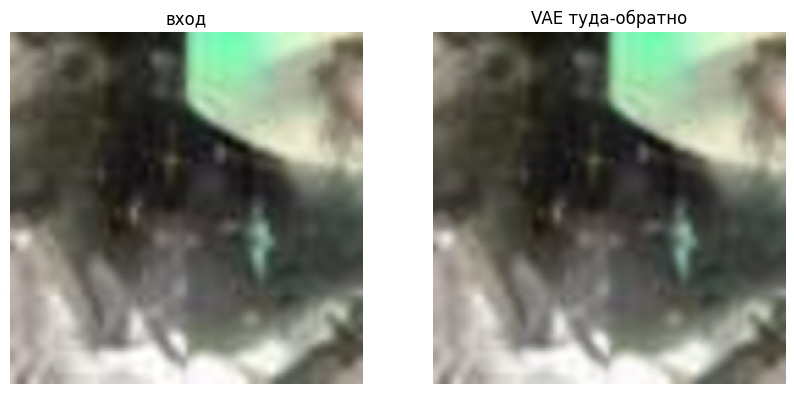

файл: /Users/h4s/Dev/UTM_Share/masters degree/computer-vision-in-Cpp/lab3_SUPIR_mask/vae_roundtrip.png


In [17]:
import matplotlib.pyplot as plt
rr = ((r[0].permute(1,2,0).float().cpu().numpy()*127.5+127.5).clip(0,255)).astype(np.uint8)
fig, ax = plt.subplots(1, 2, figsize=(10, 5))
ax[0].imshow(lq_up); ax[0].set_title("вход"); ax[0].axis("off")
ax[1].imshow(rr);    ax[1].set_title("VAE туда-обратно"); ax[1].axis("off")
plt.show()
print("файл:", os.path.abspath("vae_roundtrip.png"))

## 10. Графики и монтаж

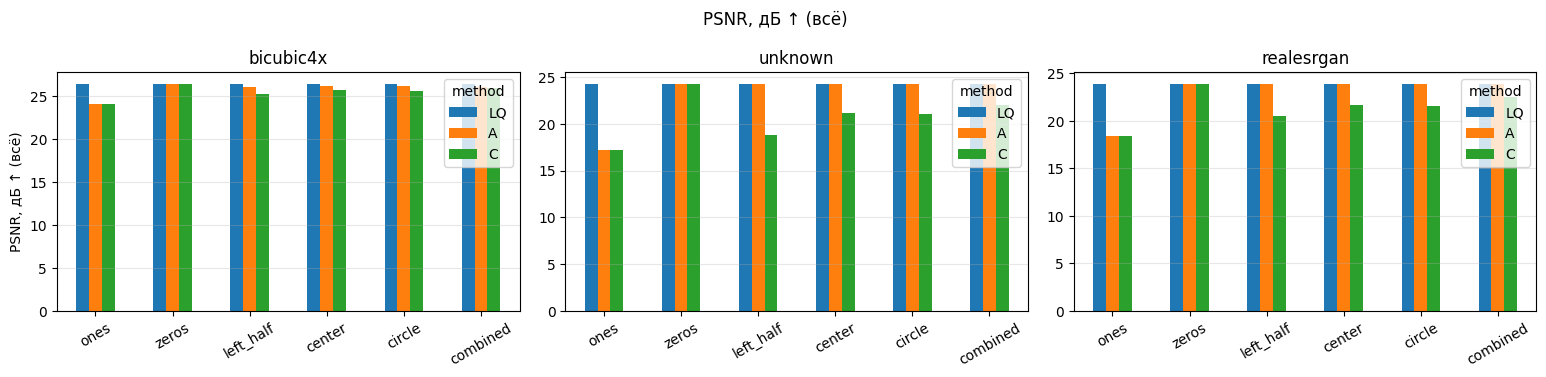

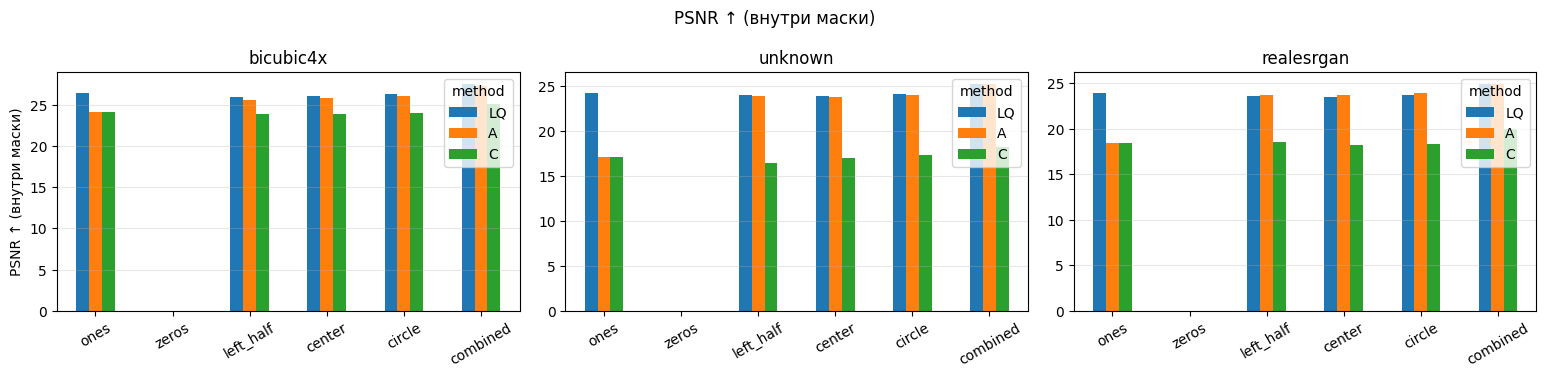

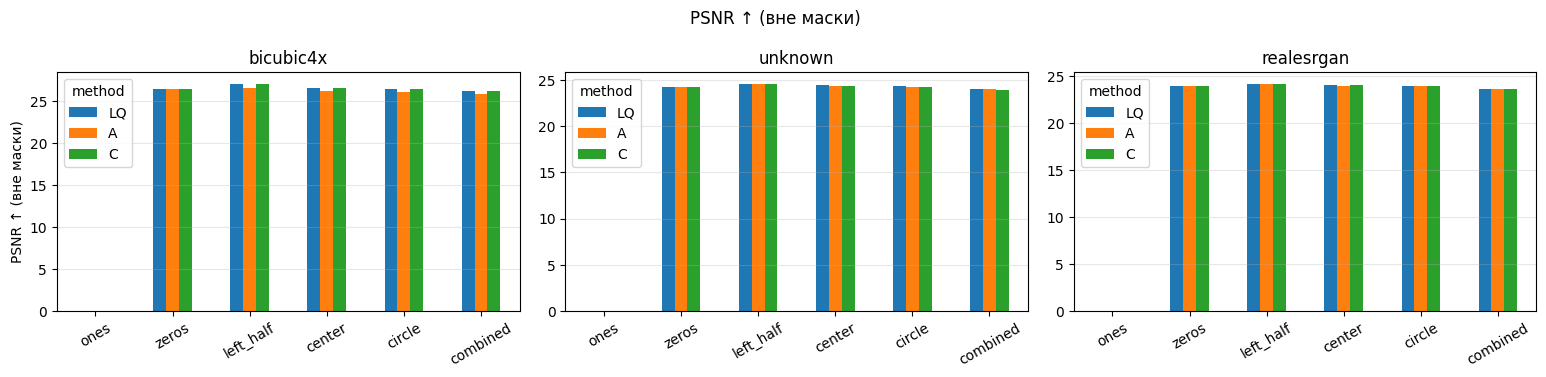

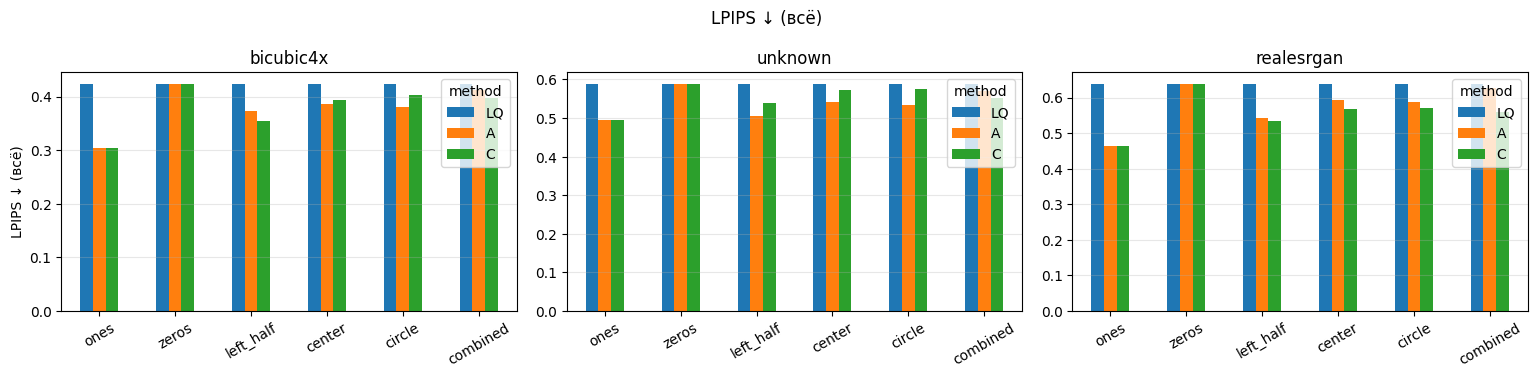

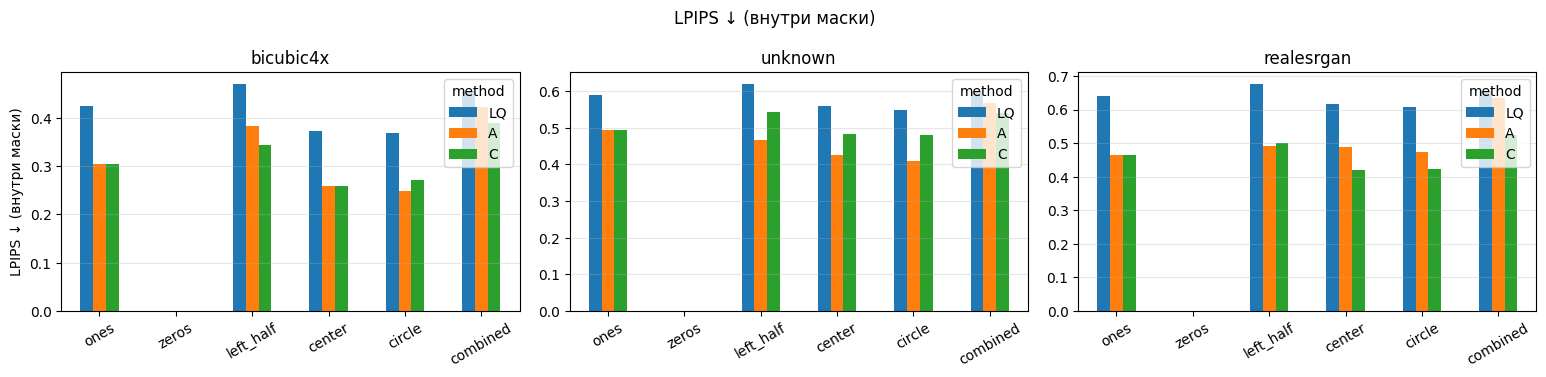

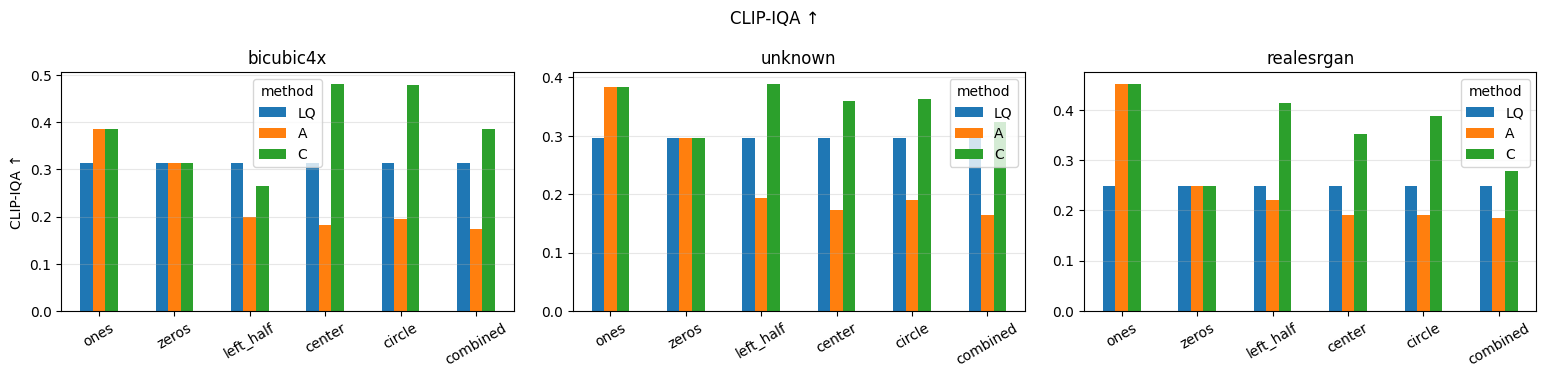

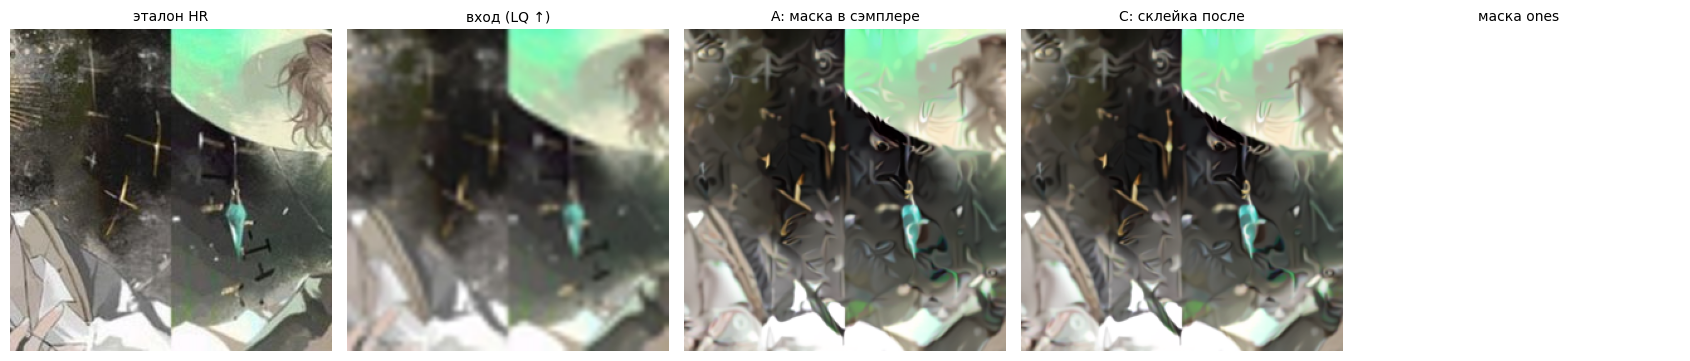

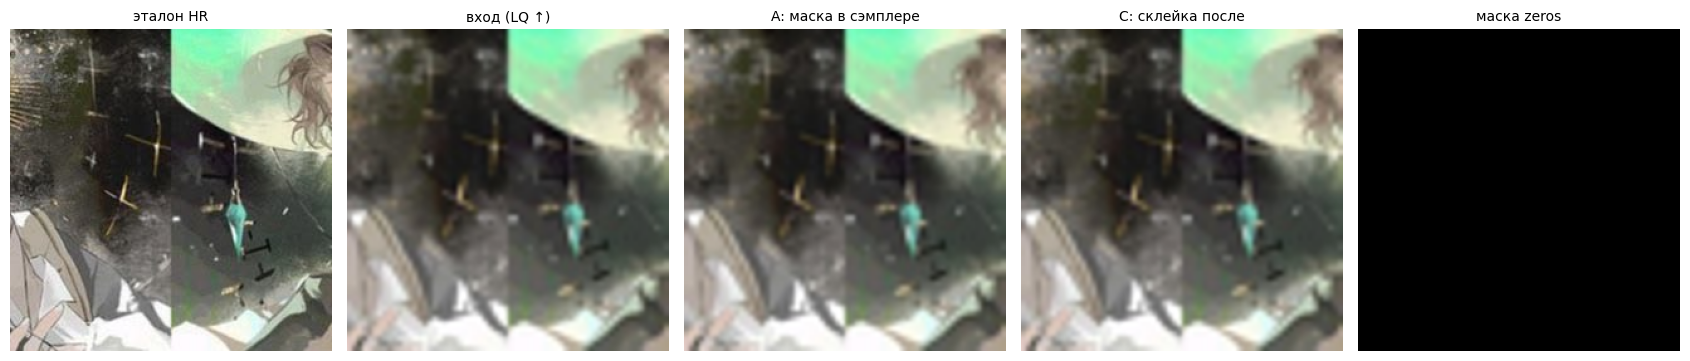

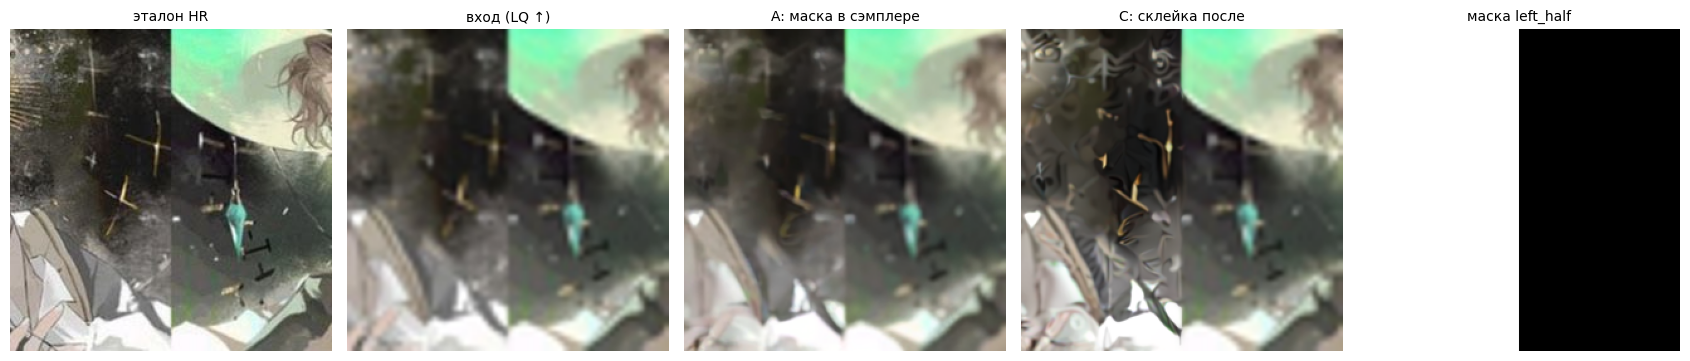

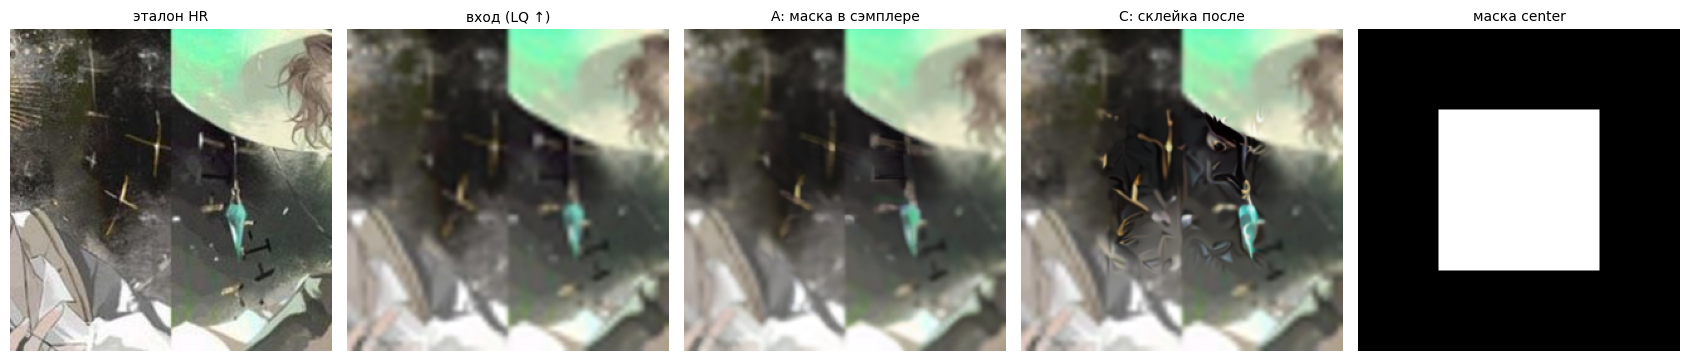

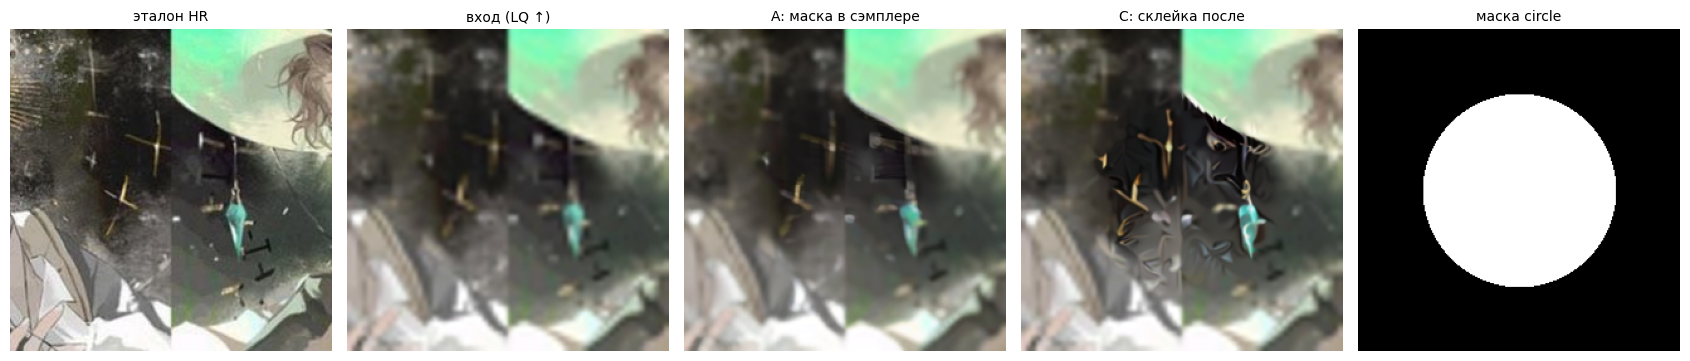

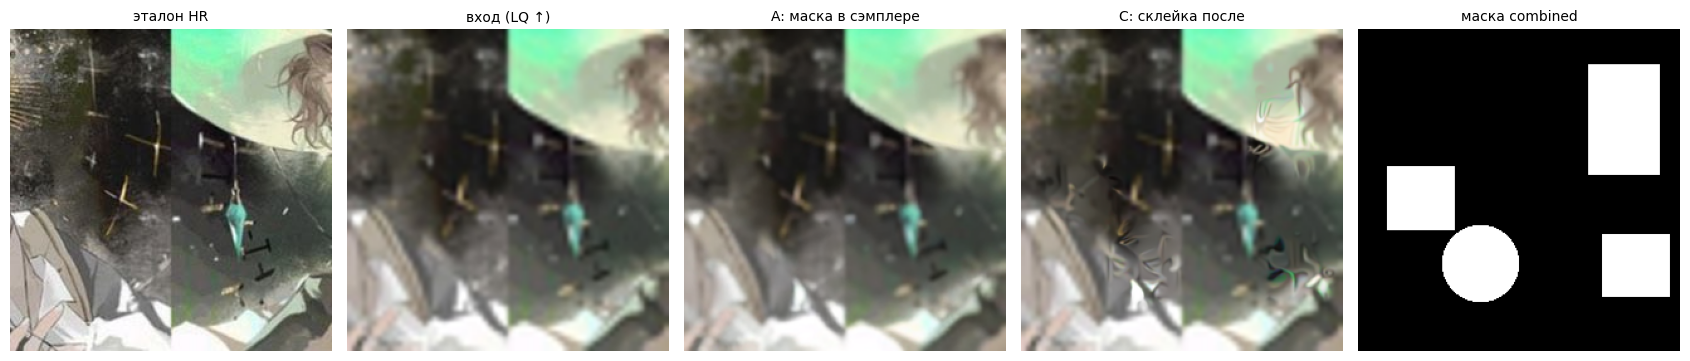

In [18]:
METRICS = [("psnr_full", "PSNR, дБ ↑ (всё)"), ("psnr_in", "PSNR ↑ (внутри маски)"), ("psnr_out", "PSNR ↑ (вне маски)"),
           ("lpips_full", "LPIPS ↓ (всё)"), ("lpips_in", "LPIPS ↓ (внутри маски)"), ("clipiqa", "CLIP-IQA ↑")]
dd = df.replace([np.inf], np.nan)
for col, title in METRICS:
    if col not in dd or dd[col].isna().all(): continue
    degs = list(dd.degradation.unique()); fig, axes = plt.subplots(1, len(degs), figsize=(5.2 * len(degs), 3.8), squeeze=False)
    for ax, deg in zip(axes[0], degs):
        piv = dd[dd.degradation == deg].pivot_table(index="mask", columns="method", values=col, aggfunc="mean").reindex(MASKS)
        piv[[c for c in ("LQ", "A", "C") if c in piv]].plot.bar(ax=ax, rot=30); ax.set_title(deg); ax.set_xlabel(""); ax.grid(axis="y", alpha=.3)
    axes[0][0].set_ylabel(title); fig.suptitle(title); fig.tight_layout(); fig.savefig(os.path.join(OUT, f"plot_{col}.png"), dpi=130); plt.show()

d0 = sorted(glob.glob(os.path.join(OUT, "images", "*")))[0]            # монтаж для первого изображения
for mk in MASKS:
    fs = [os.path.join(d0, f) for f in ("hr.png", "lq_up.png", f"A_{mk}.png", f"C_{mk}.png", f"mask_{mk}.png")]
    if not all(map(os.path.exists, fs)): continue
    fig, axs = plt.subplots(1, 5, figsize=(17, 3.6))
    for ax, f, t in zip(axs, fs, ["эталон HR", "вход (LQ ↑)", "A: маска в сэмплере", "C: склейка после", f"маска {mk}"]):
        ax.imshow(Image.open(f).convert("RGB")); ax.set_title(t, fontsize=10); ax.axis("off")
    fig.tight_layout(); fig.savefig(os.path.join(OUT, f"montage_{os.path.basename(d0)}_{mk}.png"), dpi=100); plt.show()

## Заметки
- В отчёт идут только результаты с `USE_FAKE=False`.
- Если не хватает памяти: уменьшите `CROP`, `prof["min_size"]`/`prof["max_side"]` или тайлы (`prof["sampler_tile"]`).
- Точность границы маски ограничена латентным пикселем 8 px; `HARD_COMPOSITE=True` возвращает вне маски точные пиксели исходника.
- Если ячейка 4 падает на `import sgm`, SUPIR/его зависимости не установлены в окружении ядра ноутбука.
- Экономия токенов/времени: для следующего этапа (разбор результатов) начните новый чат и приложите `results.csv`.